# TP – Analisando Grafos do SNAP
## Grafo G99 · CollegeMsg (matrícula 224215941)

Este notebook **exibe os resultados já calculados** por `scripts/run_all.py` (código em `src/`, testado contra o NetworkX).
Os valores abaixo são da execução com semente 42; os tempos da Parte II dependem do computador.
Para recalcular tudo, rode a última seção.

In [1]:
import os, json
import pandas as pd
from IPython.display import Image, display, Markdown

RAIZ = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
RES, FIG = os.path.join(RAIZ, 'resultados'), os.path.join(RAIZ, 'figuras')
pd.set_option('display.width', 200)

def mostrar(*nomes):
    for n in nomes:
        display(Image(filename=os.path.join(FIG, n + '.png'), width=900))

def tabela(nome):
    display(pd.read_csv(os.path.join(RES, nome + '.csv')))

def resultados(parte):
    return json.load(open(os.path.join(RES, parte + '.json'), encoding='utf-8'))

## 0. Determinação do grafo
Matrícula M = 224215941: soma dos dígitos = 30; últimos dois dígitos = 41.

f(M) = (30 × (41 + 1)) mod 129 = 1260 mod 129 = **99** → **G99 = CollegeMsg**.

In [2]:
M = 224215941
soma = sum(int(c) for c in str(M)); ult = M % 100
f = (soma * (ult + 1)) % 129 or 129
print(f'soma dos dígitos = {soma} | últimos dois = {ult} | f(M) = {f}  ->  G{f}')

soma dos dígitos = 30 | últimos dois = 41 | f(M) = 99  ->  G99


## 1. Descrição do grafo original e tratamento
CollegeMsg: mensagens privadas numa rede social da UC-Irvine. Cada linha `SRC DST UNIXTS` é uma mensagem.
O arquivo tem **59.835 mensagens** entre **1.899 usuários** em 194 dias.

> A tabela-índice do SNAP lista as colunas *Temporal Edges* e *Static Edges* trocadas em relação à página do dataset.
> Contamos no arquivo: 59.835 arestas temporais e 20.296 arestas estáticas dirigidas.

**Tratamentos realizados**
1. Grafo temporal → estático (união das arestas de todo o período).
2. Auto-loops: 0 encontrados (nenhum a remover).
3. Multigrafo → grafo simples, guardando o número de mensagens de cada par.
4. Versão **dirigida** (20.296 arestas) e **não dirigida** (13.838 arestas; existe aresta {u,v} se u→v ou v→u).
5. Peso da aresta não dirigida **w = 1/m** (m = mensagens do par): laço forte = distância curta. Usado só nos algoritmos que precisam de pesos.
6. Distâncias, small-world e robustez usam a **maior componente conexa** (1.893 vértices, 13.835 arestas = 99,7% dos vértices).

### 1.1 Resultado do tratamento
Do arquivo original ao grafo usado nas análises, etapa por etapa:

In [3]:
tabela('parte0_etapas')

Etapa,Vértices,Arestas,Observação
1. Arquivo original (1 linha = 1 mensagem),1899,59835,"grafo temporal, multigrafo dirigido"
2. Remoção de auto-loops,1899,59835,0 auto-loops removidos
3. Grafo estático simples dirigido,1899,20296,pares (origem→destino) únicos
4. Grafo estático simples não dirigido,1899,13838,"aresta {u,v} se u→v ou v→u"
5. Maior componente conexa,1893,13835,6 vértices fora (pares isolados)


**Amostra do arquivo original** (primeiras linhas; `data` é só a conversão de UNIXTS):

In [4]:
bruto = pd.read_csv(os.path.join(RAIZ, 'data', 'CollegeMsg.txt'), sep=' ', names=['SRC', 'DST', 'UNIXTS'])
bruto['data'] = pd.to_datetime(bruto['UNIXTS'], unit='s')
bruto.head()

SRC,DST,UNIXTS,data
1,2,1082040961,2004-04-15 14:56:01
3,4,1082155839,2004-04-16 22:50:39
5,2,1082414391,2004-04-19 22:39:51
6,7,1082439619,2004-04-20 05:40:19
8,7,1082439756,2004-04-20 05:42:36


**Arestas tratadas** (`data/processed/`): uma linha por par, com o número de mensagens. Na versão não dirigida, o peso é 1/m.

In [5]:
pd.read_csv(os.path.join(RAIZ, 'data', 'processed', 'arestas_dirigidas.csv')).head()

origem,destino,n_mensagens,primeira_msg_unixts,ultima_msg_unixts
1,2,1,1082040961,1082040961
1,3,32,1085883460,1095755904
1,30,4,1082875165,1084989181
1,32,1,1098502218,1098502218
1,36,12,1087184782,1096168791


In [6]:
pd.read_csv(os.path.join(RAIZ, 'data', 'processed', 'arestas_nao_dirigidas.csv')).head()

u,v,n_mensagens_total,peso_1_sobre_m
1,2,1,1
1,3,67,0.014925
1,30,5,0.2
1,32,2,0.5
1,36,18,0.055556


In [7]:
tabela('parte0_estatisticas')

variável,mín,mediana,média,máx
mensagens por par (não dirigido),1,2,4.324,184
peso w = 1/m,0.0054348,0.5,0.5624,1


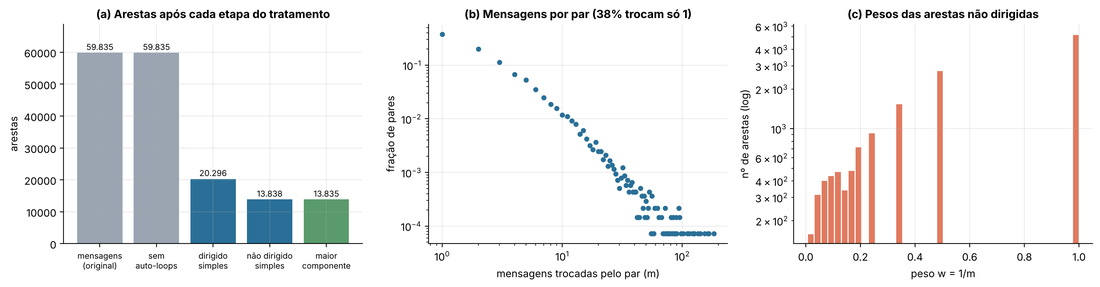

In [8]:
mostrar('tratamento')

**Comentários.**
- O arquivo não tem auto-loops, então nenhuma aresta saiu nessa etapa. O grande corte vem de **multigrafo → grafo simples**: as 59.835 mensagens viram 20.296 pares dirigidos, e estes viram 13.838 pares não dirigidos.
- 38% dos 13.838 pares trocaram **uma única mensagem**; a mediana é 2 e há pares com até 184. Por isso o peso 1/m varia de 0,005 a 1, com a mediana em 0,5.
- Dos pares com mensagem em algum sentido, 64% dos arcos têm resposta (reciprocidade).
- A maior componente tem 1.893 vértices: o tratamento só descarta 6 vértices (3 pares isolados), então não perdemos informação relevante.

## 2. Parte I – Análise estrutural
### 2.1 Tabela de medidas (computadas × não computadas)

In [9]:
tabela('parte1_tabela')

Medida,Computada?,Valor
Número de vértices,Sim,"1,899"
Número de arestas,Sim,"20,296 (dirigido) / 13,838 (não dirigido)"
"Grau mínimo, máximo e médio",Sim,"1, 255, 14.57"
Distribuição de graus,Sim,figura distribuicao_graus
Densidade,Sim,0.00768
Número de componentes conexas,Sim,4
Tamanho de cada componente,Sim,"[1893, 2, 2, 2]"
Diâmetro,"Sim (maior componente, exato)",8
Raio,"Sim (maior componente, exato)",4
Comprimento médio dos caminhos,"Sim (maior componente, exato)",3.0552


**Comentários.**
- Quase toda a rede está numa só componente: 1.893 de 1.899 vértices (99,7%); as outras três componentes são pares isolados.
- Distribuição de graus muito assimétrica: grau médio 14,57, mediana 5, máximo 255. Poucos vértices concentram muitas conexões.
- Densidade 0,00768: grafo esparso. Reciprocidade 63,6%: quase dois terços dos contatos são correspondidos.
- Assortatividade de grau -0,188 (negativa): vértices de grau alto se ligam a vértices de grau baixo, típico de rede com "emissores".
- Distâncias exatas na maior componente: diâmetro 8, raio 4, caminho médio 3,055. Mais da metade dos pares está a 3 passos.
- Clusterização média 0,109, transitividade 0,057 e 14.319 triângulos.
- k-core máximo 20 (201 vértices): existe um núcleo coeso e uma periferia grande.

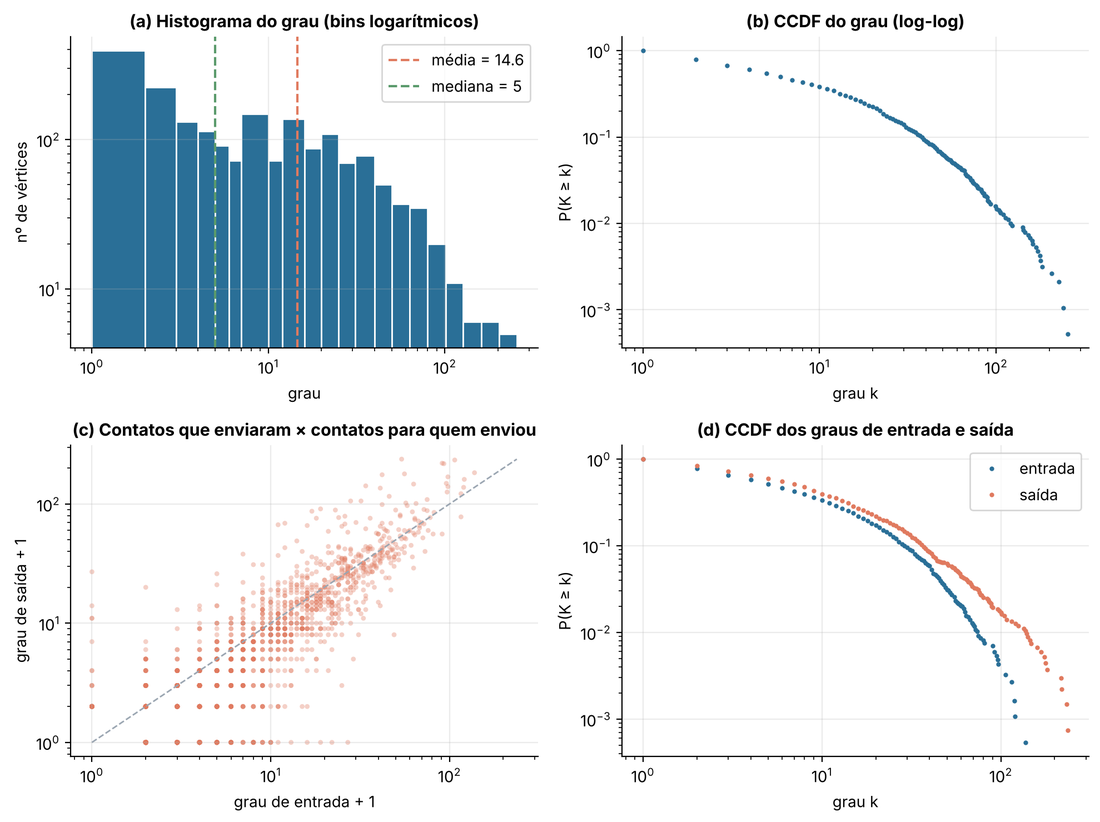

In [10]:
mostrar('distribuicao_graus')

**Distribuição de graus.** (a) histograma em bins logarítmicos; (b) CCDF em log-log; (c) quem recebe de muitos
nem sempre envia para muitos; (d) a cauda dos graus de saída é mais pesada que a de entrada.

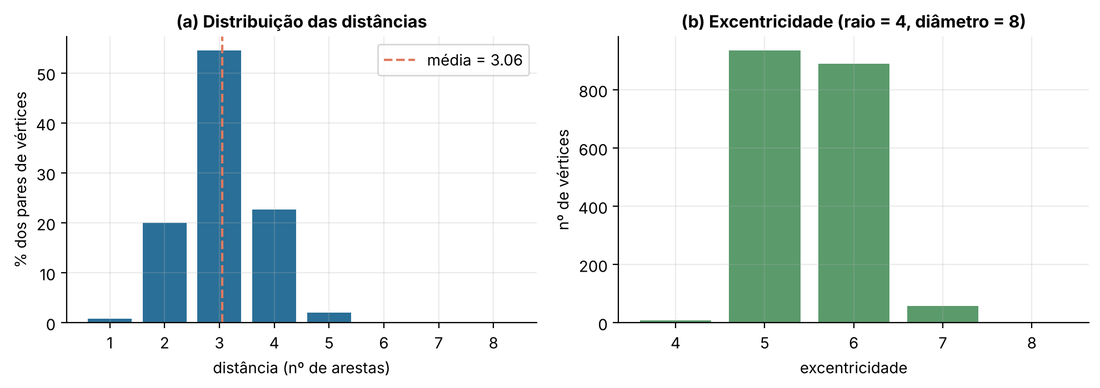

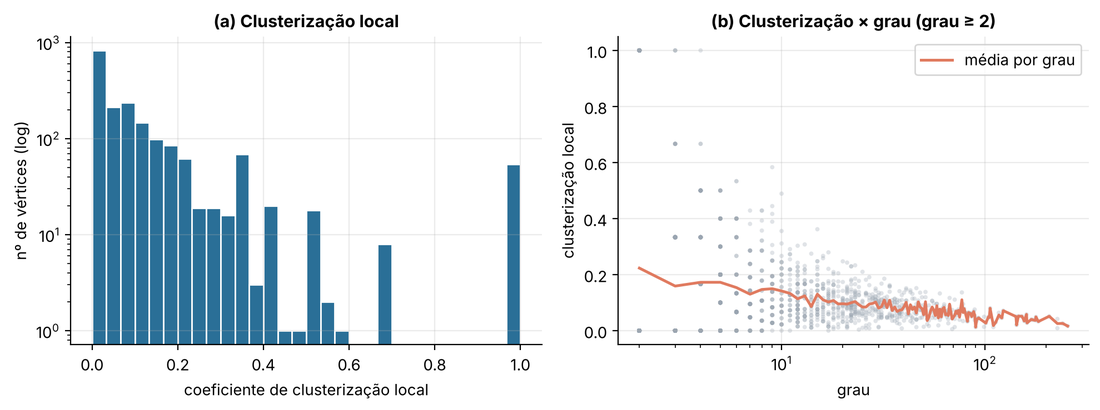

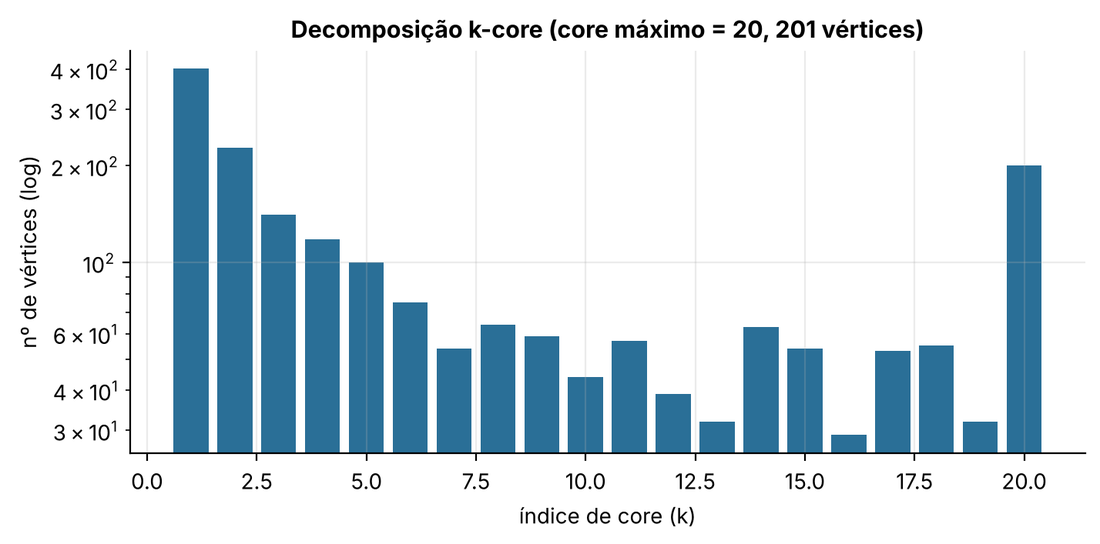

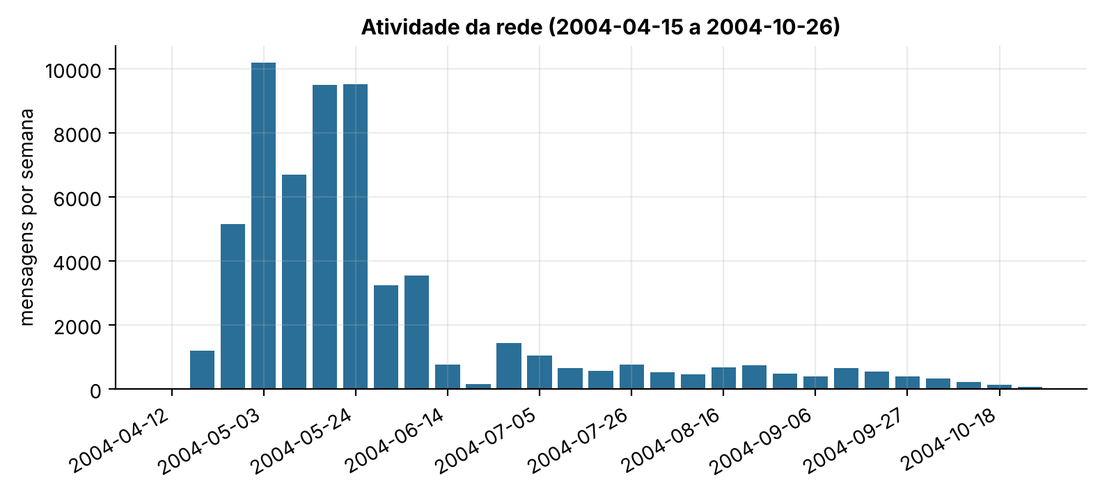

In [11]:
mostrar('distancias', 'clusterizacao', 'kcore', 'atividade_semanal')

**Comentários.** As distâncias concentram-se em 3 passos (barra mais alta), com cauda curta até 8. A clusterização local
**decresce com o grau**: vértices com poucos contatos têm vizinhos que se conhecem, e os hubs conectam grupos que não se conhecem.
A atividade é muito concentrada no tempo: **79,7% das mensagens** ocorrem nas primeiras 8 semanas.

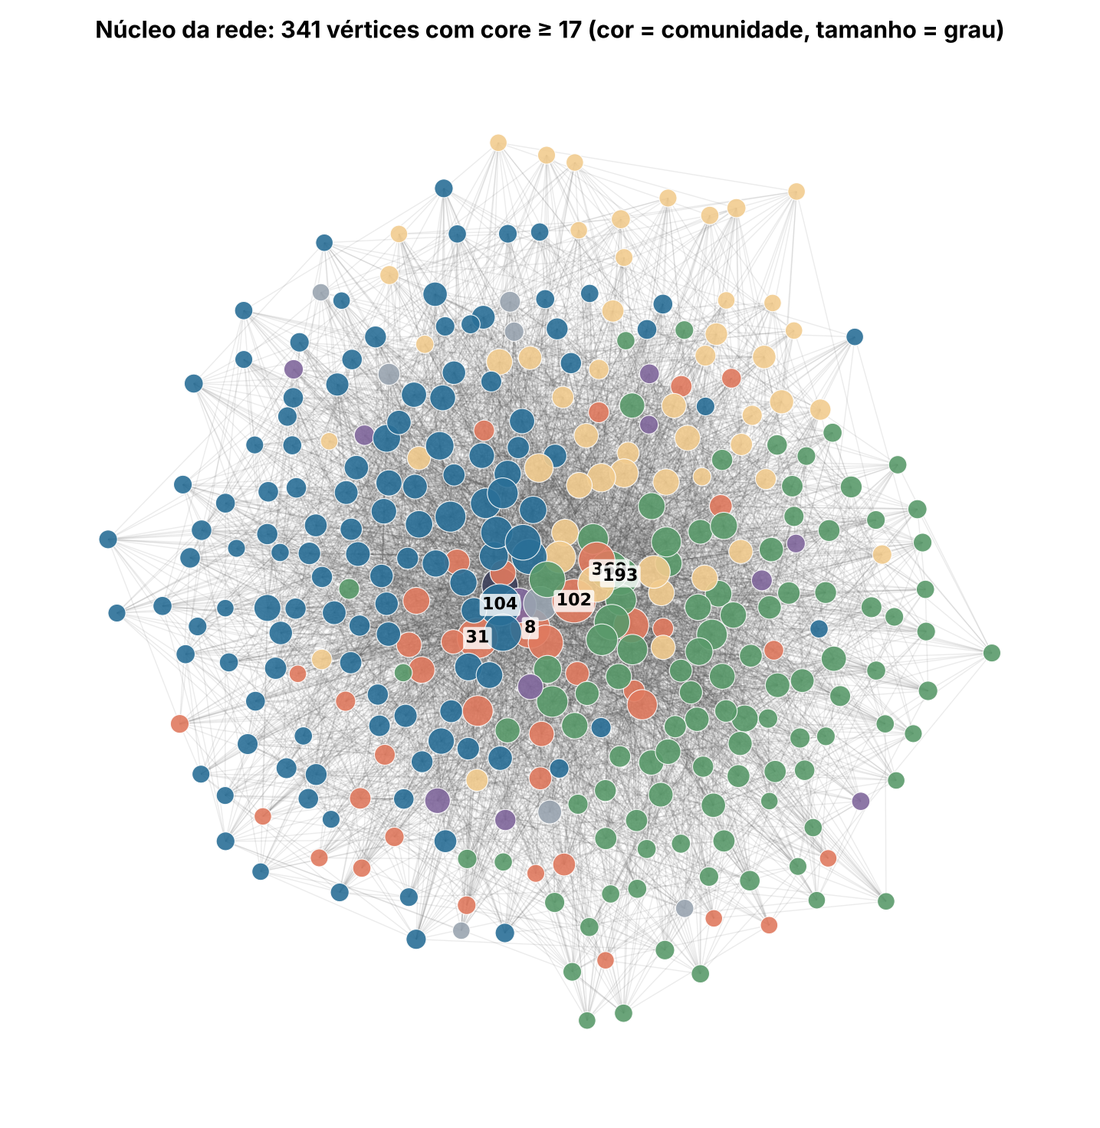

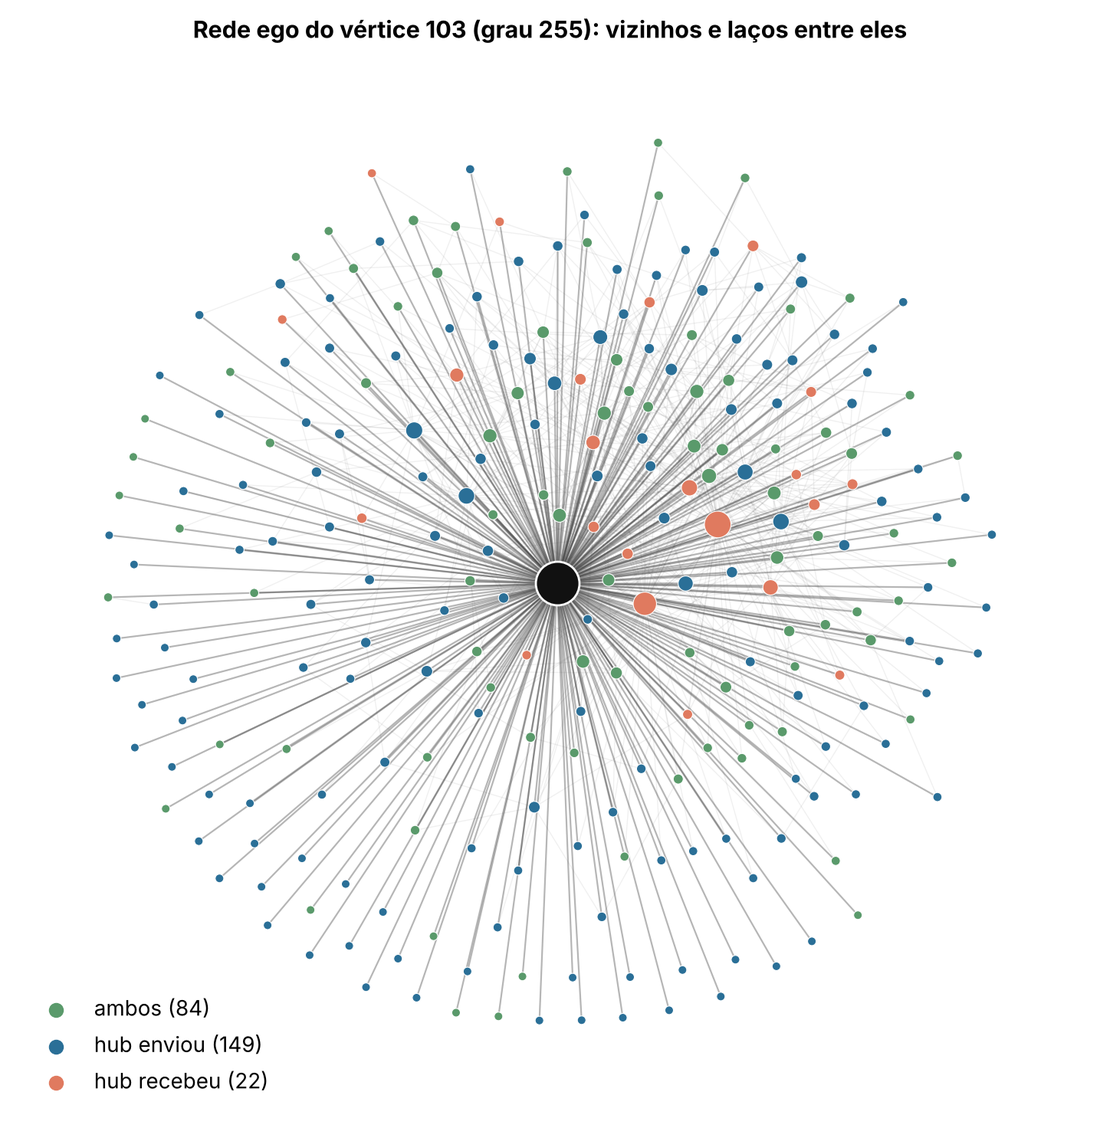

In [12]:
mostrar('grafo_nucleo', 'grafo_ego_hub')

**Visualizações (versões reduzidas).** O grafo completo é ilegível, então mostramos (i) o **núcleo** com 341 vértices de core ≥ 17,
colorido por comunidade (Louvain, 9 comunidades no núcleo; modularidade global da maior componente 0,26), e
(ii) a **rede ego do maior hub** (vértice 103, grau 255): enviou mensagens a 149 contatos que não responderam,
recebeu de 22 sem responder e trocou mensagens nos dois sentidos com 84.

## 3. Parte II – Algoritmos da disciplina
Todos implementados à mão e validados contra o NetworkX (`pytest`). Grafo: maior componente (1.893 vértices, 13.835 arestas).

### 3.1 O que cada algoritmo encontrou

In [13]:
tabela('parte2_resumo')

Algoritmo,Aplicado?,Resultado
BFS,Sim,maior componente; alcança 1893 vértices
DFS,Sim,maior componente; visita 1893 vértices
Eulerianidade,Sim,não euleriano; 1062 vértices de grau ímpar (não dirigido); dirigido: 1692 com entrada ≠ saída
Dijkstra,Sim (pesos 1/m > 0),distância máxima 3.430 a partir da fonte
Bellman-Ford,Sim (pesos 1/m),sem ciclo negativo; 7 passadas até convergir (pior caso 1892)
Floyd-Warshall,Sim,"grafo completo (1893 vértices), versão numpy; python puro só com n = 150"
Tarjan (SCC),Sim,601 componentes fortemente conexas; maior com 1294
Tarjan (pontes/articulações),Sim,395 pontes e 220 pontos de articulação
Kruskal / Prim,Sim,"árvore geradora mínima, peso 746.150"


- **Eulerianidade:** a rede **não é euleriana**: 1.062 vértices têm grau ímpar (um circuito exige 0; um caminho, 2).
  No grafo dirigido, 1.692 vértices têm grau de entrada ≠ saída.
- **Tarjan:** 601 componentes fortemente conexas; uma gigante com 1.294 vértices e 595 vértices isolados (SCC de tamanho 1).
  Também encontramos 395 pontes e 220 pontos de articulação (vértices cuja remoção desconecta a rede).
- **Pesos:** w = 1/m é positivo, logo Dijkstra se aplica. Bellman-Ford confirmou a ausência de ciclo negativo e convergiu em 7 passadas (pior caso 1.892).
- **Árvore geradora mínima:** Kruskal e Prim deram o mesmo peso (746,150) com 1.892 arestas.

### 3.2 Tempo real (média, desvio padrão e IC 95%)
Algoritmos de fonte única foram repetidos a partir de 30 fontes aleatórias; os demais, 30 vezes (n ≥ 30 → IC pela **Normal**).
O Floyd-Warshall completo foi repetido 5 vezes (n < 30, σ desconhecido → IC pela **t-Student**).
Cada medição descarta uma execução de aquecimento e desliga o coletor de lixo.

In [14]:
tabela('parte2_tempos')

algoritmo,complexidade,repeticoes,media,dp,ic_lo,ic_hi,distribuicao_ic
BFS,O(V + E),30,0.0010887,0.00016827,0.0010285,0.001149,Normal (Z)
DFS,O(V + E),30,0.0017745,0.00037854,0.001639,0.0019099,Normal (Z)
Eulerianidade,O(V + E),30,0.0013674,0.00021758,0.0012895,0.0014452,Normal (Z)
Dijkstra,O((V + E) log V),30,0.0043196,0.00053825,0.004127,0.0045122,Normal (Z)
Bellman-Ford,O(V·E),30,0.013997,0.0012151,0.013562,0.014431,Normal (Z)
Tarjan (SCC),O(V + E),30,0.0028233,0.0002663,0.0027281,0.0029186,Normal (Z)
Tarjan (pontes),O(V + E),30,0.0038007,0.00038984,0.0036612,0.0039402,Normal (Z)
Kruskal,O(E log E),30,0.0078805,0.00079471,0.0075962,0.0081649,Normal (Z)
Prim,O(E log V),30,0.013274,0.00094586,0.012936,0.013613,Normal (Z)
Floyd-Warshall,O(V³),5,23.621,1.2529,22.066,25.177,t-Student


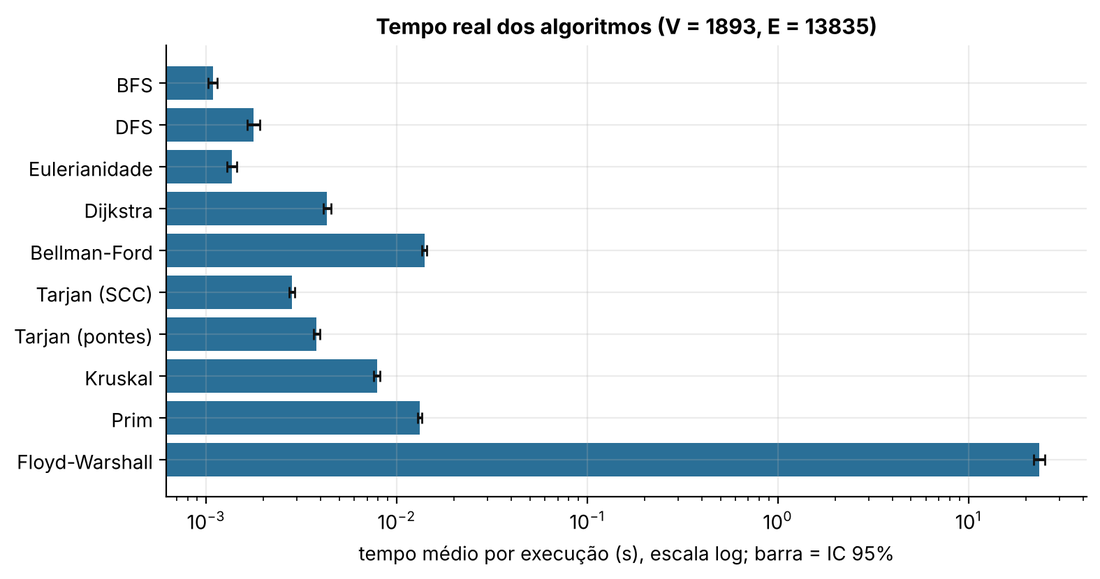

In [15]:
mostrar('tempos_algoritmos')

**Comentários.** Os algoritmos lineares (BFS, DFS, Tarjan, Eulerianidade) levam alguns milissegundos; Dijkstra, Kruskal, Prim e Bellman-Ford,
algumas dezenas de milissegundos; o **Floyd-Warshall é de outra ordem de grandeza** (≈ 24 s para 1.893 vértices), como o V³ prevê.
Com n = 150, a versão vetorizada em numpy é ≈ 46 vezes mais rápida que o Python puro, mantendo o mesmo número de operações.

### 3.3 Complexidade teórica × observada
Medimos cada algoritmo em subgrafos conexos de tamanhos crescentes e ajustamos a reta log(tempo) × log f(V,E).
Se o tempo seguir a teoria, a inclinação é ≈ 1.

In [16]:
tabela('parte2_inclinacoes')

algoritmo,complexidade_teorica,inclinacao_loglog
BFS,V + E,0.93831
DFS,V + E,0.87447
Dijkstra,(V+E) log V,0.81031
Bellman-Ford,V·E,0.64735
Kruskal,E log E,0.8871
Prim,E log V,1.0003
Tarjan (pontes),V + E,1.0062
Floyd-Warshall,V³,0.99238


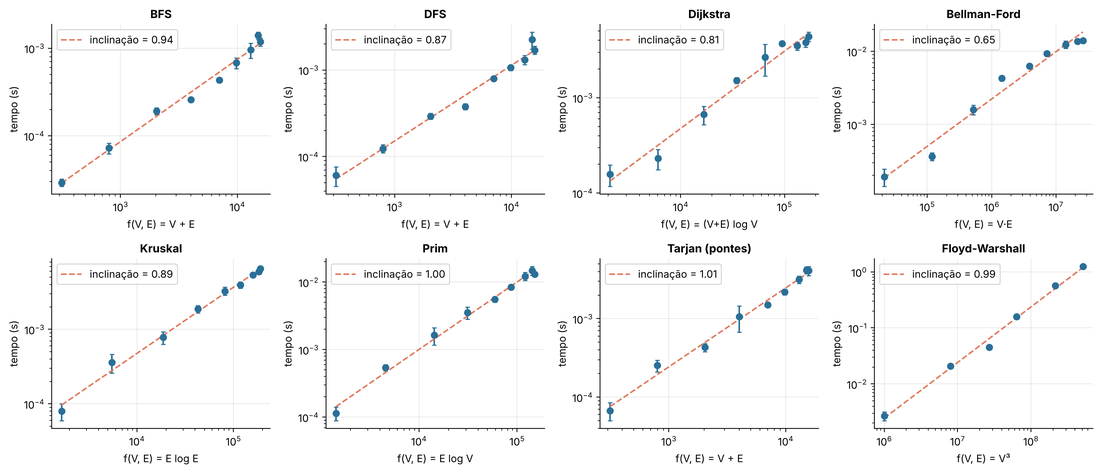

In [17]:
mostrar('complexidade_observada')

**Comentários.** Tarjan (pontes), Prim e Floyd-Warshall ficam muito perto de 1. BFS, DFS, Dijkstra e Kruskal ficam um pouco abaixo (≈ 0,8 a 0,95):
em Python há custos fixos por chamada que pesam mais nos grafos pequenos. **Bellman-Ford (≈ 0,65)** fica bem abaixo porque V·E é o *pior caso*:
com parada antecipada ele converge em poucas passadas (próximo ao diâmetro), então o tempo cresce quase como E.
O pior caso só apareceria em grafos com caminhos mínimos muito longos.

## 4. Parte III – Análise estrutural
### 4.1 O grafo apresenta indícios de small-world?
Comparamos o grafo (maior componente) com dois grafos aleatórios de mesmo n e m, **implementados à mão**:
**Erdős-Rényi G(n,m)** e um **modelo nulo com a mesma sequência de graus** (reconexão de arestas). Em cada caso, 20 amostras;
o caminho médio dos nulos foi estimado com BFS de 500 fontes. Índice σ = (C/C_rand)/(L/L_rand).

In [18]:
tabela('parte3_smallworld')

Unnamed: 0,valor
n,1893
m,13835
grau_medio,14.617
C,0.10975
L,3.0552
C_er_teorico,0.0077216
L_er_teorico,2.8133
C_er,0.0076201
C_er_dp,0.00037972
L_er,3.0833


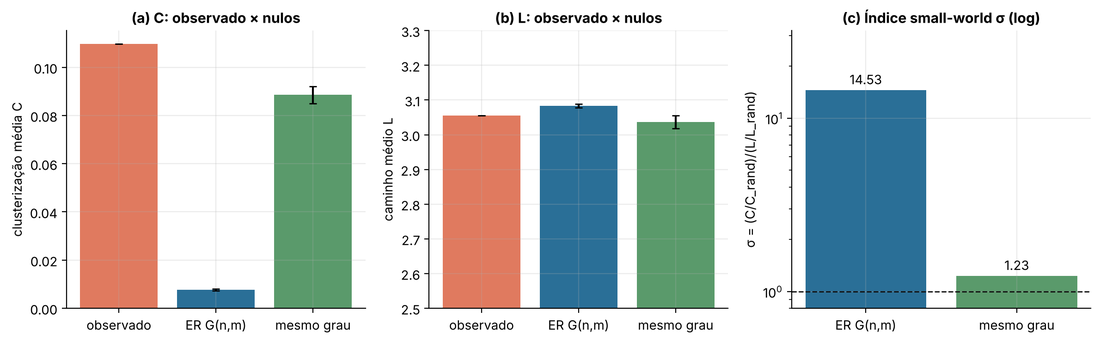

In [19]:
mostrar('smallworld')

**Resposta.**
- **Contra G(n,m): sim, com folga.** L = 3,055 é praticamente igual a L_ER = 3,083 (razão 0,991), enquanto C = 0,110 é **14,4 vezes** maior que C_ER = 0,0076. Assim, σ ≈ 14,5 ≫ 1 e a definição do Apêndice A é satisfeita.
- **Contra a mesma sequência de graus: apenas ligeiramente.** C é só 1,24 vez o do nulo (σ ≈ 1,23). **Quase toda a clusterização vem da heterogeneidade dos graus** (hubs), e não de comunidades fechadas.
- **Faz sentido?** Sim, para uma rede de mensagens: poucas pessoas muito ativas encurtam as distâncias e criam grupos em torno delas.
- **Implicação prática:** qualquer usuário alcança outro em ≈ 3 passos (diâmetro 8); informação, convites ou spam se espalham muito rápido, e os hubs são decisivos nessa difusão.

### 4.2 A distribuição de graus sugere uma lei de potência?
Ajuste discreto por **máxima verossimilhança** (não por regressão no log-log, que é viesada), k_min escolhido pelo menor KS,
p-valor por bootstrap (200 amostras sintéticas) e razão de verossimilhança de Vuong contra exponencial e lognormal.

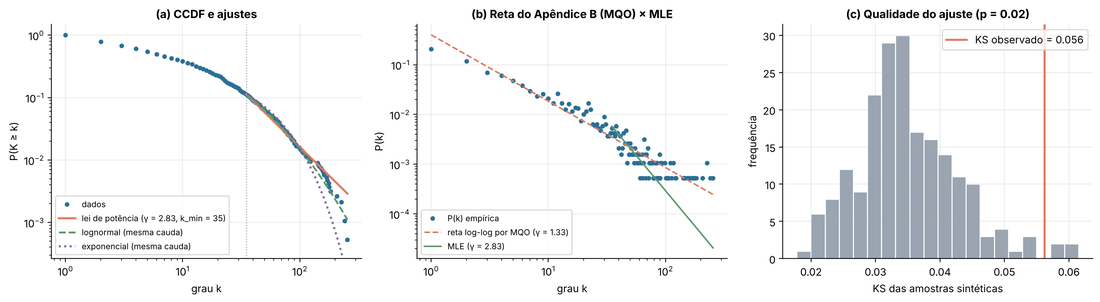

In [20]:
mostrar('lei_de_potencia')

In [21]:
pd.DataFrame(resultados('parte3')['q2']['sensibilidade_kmin'])

kmin,gamma,ks,n_cauda
1,1.4385,0.15025,1899
2,1.5552,0.1373,1505
3,1.6322,0.13854,1281
5,1.7647,0.13989,1035
8,1.9219,0.12297,816
10,2.0282,0.11327,723
15,2.2512,0.10005,545
20,2.4587,0.073791,427
30,2.7245,0.061688,265


**Resposta: não há evidência de lei de potência; a cauda é pesada, mas não livre de escala.**
- Melhor ajuste: γ = 2,83 ± 0,13 com k_min = 35, ou seja, só 214 vértices (11,3%) estão na cauda.
- **Qualidade do ajuste: p = 0,02 < 0,10** → a lei de potência é rejeitada.
- Contra a **lognormal**: R = -3,95 (p = 0,07): a lognormal ajusta melhor, com significância apenas marginal. Contra a **exponencial**: R = 2,04 (p = 0,71): indistinguíveis na cauda curta.
- **Instabilidade:** γ cresce de 1,44 a 2,72 quando k_min vai de 1 a 30. Não há uma região do gráfico com declive constante.
- A reta log-log por mínimos quadrados dá γ = 1,33, valor enganoso: a CCDF não é linear e o MQO é dominado pelos pontos ruidosos da cauda.
- Existem **hubs** (grau máximo 255 contra média 14,6), mas a distribuição se curva para baixo (cauda "encolhida").

### 4.3 Robustez
Política: trabalhar na **maior componente conexa** (n = 1.893); r = ⌈0,05 n⌉ = **95** vértices removidos.
Métricas: **A** tamanho da maior componente (fração de n; A_rel divide por n − r), **B** número de componentes, **C** caminho médio na maior componente (exato), **D** fração de isolados.
Remoção aleatória: T = 30 repetições. Ataque: ranking fixo por **grau**, **intermediação** (Brandes) e **PageRank**.

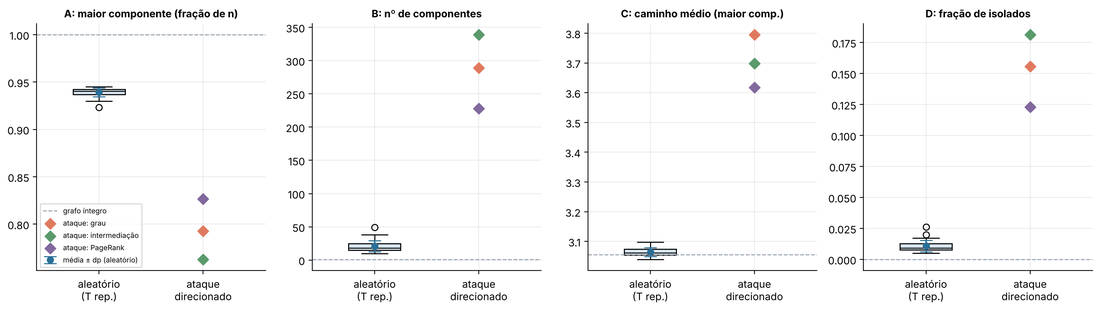

In [22]:
mostrar('robustez_boxplot')

In [23]:
tabela('parte3_robustez_aleatoria')

metrica,media,dp,min,max
A,0.93916,0.0046595,0.9234,0.94506
A_rel,0.98878,0.0049057,0.97219,0.99499
B,20.833,8.4693,10,49
C,3.0641,0.01507,3.0395,3.0981
D,0.010864,0.0045904,0.0050056,0.02614


In [24]:
tabela('parte3_robustez_ataques')

estrategia,A,A_rel,B,C,D
íntegro,1,1,1,3.0552,0
ataque grau,0.79292,0.83482,289,3.795,0.15573
ataque intermediação,0.76281,0.80311,339,3.6979,0.18131
ataque PageRank,0.82673,0.87041,228,3.6178,0.12291


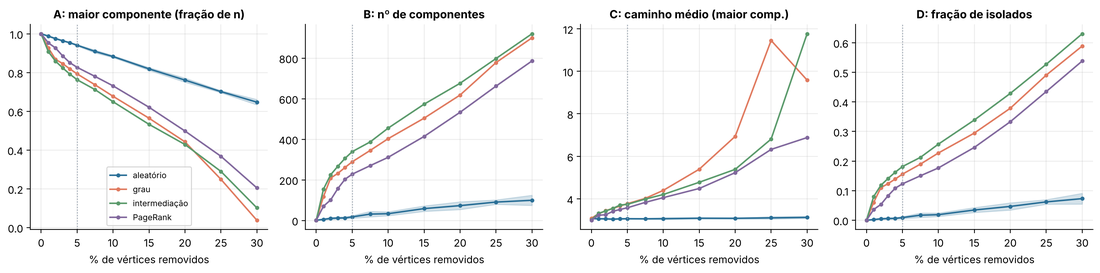

In [25]:
mostrar('robustez_curvas')

**Resposta.**
- **Falhas aleatórias de 5%: a rede é robusta.** A = 0,939 ± 0,005 (o máximo possível seria 0,95); entre os vértices que restam, 98,9% continuam na maior componente.
  B = 20,8 ± 8,5 componentes, C = 3,064 (era 3,055) e apenas 1,1% de isolados.
- **Ataque aos 5% mais centrais: a rede é vulnerável.** Por intermediação, A cai para 0,763 (B = 339, 18,1% isolados); por grau, A = 0,793 (B = 289); por PageRank, A = 0,827 (B = 228).
  O caminho médio sobe para 3,80. Como S_rand ≫ S_cent e c_cent ≫ c_rand, o padrão é o de redes com hubs.
- **Curvas:** removendo 20% dos vértices, a maior componente retém 76% (aleatório) contra 44% (grau); com 30%, 65% contra 4% (grau) e 10% (intermediação).
- Os rankings concordam bastante: 82% dos 5% de maior grau também estão entre os 5% de maior intermediação.
- Nas curvas, C é estimado com 200 fontes e fica instável quando a rede se fragmenta (> 20%).

### 4.4 A descoberta mais interessante: os "hubs" não são conversadores, são emissores
Os vértices de grau alto não se comportam como centros sociais, e sim como emissores em massa:
- Os 20 usuários que mais enviaram escreveram a ≈ 159 pessoas em média, mas só 43% dos destinatários responderam (contra 64% na rede toda).
- A reciprocidade cai com o grau: ≈ 74–79% nas faixas de grau 2 a 31, e **44% nos vértices de grau ≥ 128**.
- Os 5% que mais enviam produzem **47% das mensagens**; 38% dos pares trocam uma única mensagem, e os 10% de pares com ≥ 10 mensagens concentram 46% do tráfego.
- Quando há resposta, ela é rápida: a mediana entre a 1ª mensagem de cada sentido é de 3,9 h (6.458 pares recíprocos).
- Temporalmente, 80% das mensagens ocorrem nas 8 primeiras semanas (pico e depois cauda).

**Ligação com os resultados anteriores:** são justamente esses emissores que conectam a rede. Removê-los fragmenta o grafo (seção 4.3), e eles explicam a clusterização "herdada" dos graus (seção 4.1).

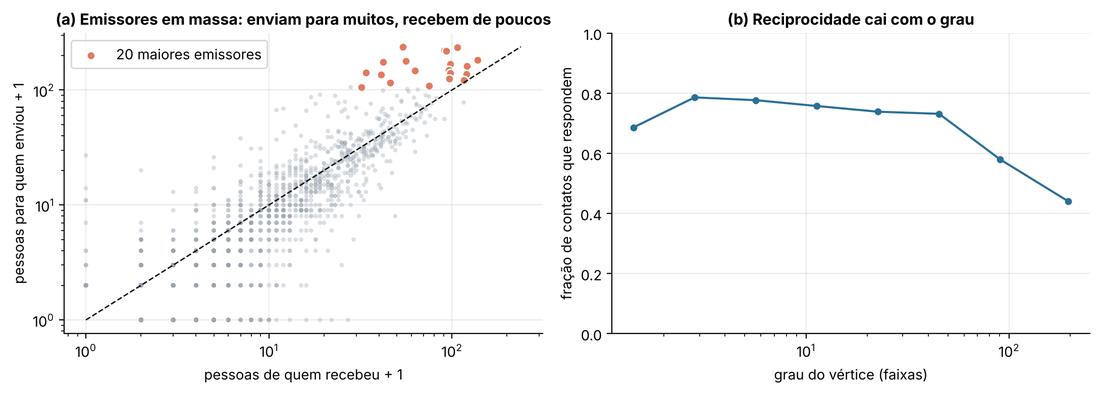

In [26]:
mostrar('descobertas')

### 4.5 (Extra) O grafo se aproxima de algum modelo clássico?
Comparamos com ER, Barabási-Albert (k = 7), Watts-Strogatz (k = 14, p = 0,1) e o nulo de mesmo grau. Cada modelo: 10 amostras, mesmo n e m (≈) da maior componente.

In [27]:
tabela('parte3_modelos')

modelo,C,L,grau_max,grau_dp,KS_grau,m
observado,0.10975,3.0552,255,24.486,0,13835
ER,0.0076293,3.0788,28.9,3.8102,0.54818,13835
BA,0.030689,2.9076,196.6,14.486,0.53936,13202
WS,0.50918,4.1426,18.6,1.1595,0.64205,13251
mesmo grau,0.088956,3.033,255,24.486,0,13835


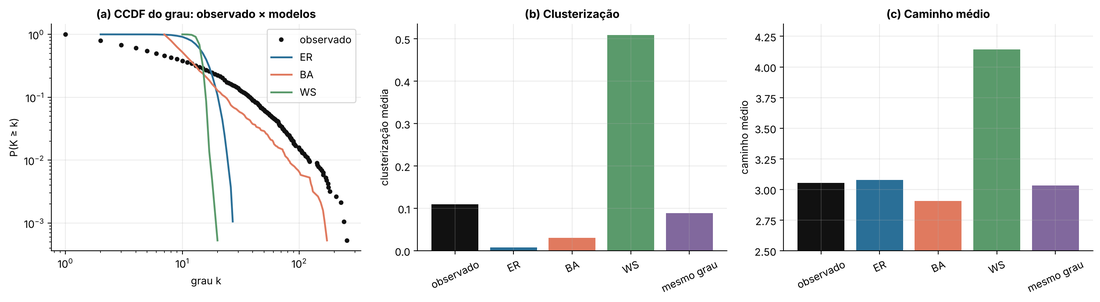

In [28]:
mostrar('modelos_classicos')

**Resposta: nenhum modelo clássico reproduz a rede.**
- **ER:** acerta L, mas C (0,0076) é ≈ 14× menor e não há hubs (grau máx. ≈ 29 contra 255).
- **Barabási-Albert:** reproduz hubs (≈ 197) e caminhos curtos (2,91), mas C = 0,031 é ≈ 3,6× menor e o grau mínimo é k = 7 (a rede real tem muitos vértices de grau 1 a 5).
- **Watts-Strogatz:** C = 0,51 é alto demais, L = 4,14 é longo demais e não há hubs.
- **Mesma sequência de graus:** é o que mais se aproxima (C = 0,089 vs 0,110; L = 3,03 vs 3,06), mostrando que **a heterogeneidade dos graus explica quase toda a estrutura**; falta só um pouco de clusterização local.

## 5. Discussão crítica e limitações
- **Tempo ignorado.** O grafo estático une 193 dias; dois usuários podem estar ligados por um caminho que nunca existiu em ordem temporal. Distâncias e difusão reais seriam maiores. Além disso, ≈ 80% das mensagens ocorrem em 8 semanas, então a rede muda muito.
- **Direção.** Distâncias, clusterização e robustez usam a versão não dirigida. Com direção (Tarjan), só 1.294 vértices formam uma componente fortemente conexa.
- **Pesos.** w = 1/m é uma escolha nossa; outra definição (por exemplo, intervalo entre mensagens) mudaria Dijkstra, Floyd-Warshall e a árvore geradora, mas não os resultados sem pesos.
- **Estimativas.** O caminho médio dos nulos (small-world) e das curvas de robustez usa amostras de fontes; os valores do grafo observado são exatos.
- **Robustez com ranking fixo.** O ataque usa a centralidade calculada uma vez, como pede o enunciado. Um ataque **adaptativo** (recalculando a cada remoção) seria ainda mais destrutivo.
- **Lei de potência.** Com só 214 vértices na cauda, testes de cauda têm baixa potência; por isso reportamos também o ajuste por faixa de k_min.

## 6. Conclusão
O G99 é uma rede esparsa e quase toda conexa, com caminhos curtos (L ≈ 3, diâmetro 8) e alguns hubs muito ativos.
É small-world em relação a um grafo aleatório, mas essa propriedade vem sobretudo da heterogeneidade dos graus. A distribuição de graus tem cauda pesada **sem ser uma lei de potência**.
A rede é robusta a falhas aleatórias e **frágil a ataques aos hubs**, que são emissores em massa (baixa reciprocidade). Nenhum modelo clássico a descreve; o modelo de mesmo grau é o mais próximo.

## 7. Recalcular tudo (opcional)
Roda o pipeline completo (~7 min). Execute em uma máquina sem outras tarefas pesadas, porque a Parte II mede tempo.

In [29]:
# remova o '#' da linha abaixo para recalcular (grava em resultados/ e figuras/)
# %run ../scripts/run_all.py